# NCA K5 | Spatially matched seasonal-median XGBoost (2016–2026)

**Independent 45-spectral-feature seasonal representation (48 predictors including year and coordinates); no harmonic predictors.**

- Combine the original vegetation master (`PlotID`) with authoritative 2026 vegetation (`Plot` → `PlotID`).
- Read annual monthly-median exports; exported `plot_id` is *not used* because it is blank.
- Filter vegetation locations to the coordinate-domain represented by the **2016 historical export** (historical acquisition footprint ∩ `keepMask`), including all later field years. The 2016 export is mandatory for this analysis.
- Join vegetation plot-years to **same-year** median observations using 2 m spatial tolerance in **EPSG:26911**; flag ambiguous or missing matches.
- Save a definitive all-vegetation master and model only observations with complete seasonal features and valid cover + K5 membership responses.
- Retain the existing grouped held-out XGBoost tasks: seven cover fractions, five-dimensional K5 membership, and direct K5 state classification.

**Spatial assumptions:** both vegetation and median `Easting/Northing` are point coordinates in EPSG:26911. Matching within 2 m is an identity-tolerance choice, *not* a spatial interpolation. Cross-year analyses may still be affected by the different spatial supports of field plots and 10 m pixels. No synthetic spectral data or imputation are used. The split is grouped by coordinate-defined site, not spatially blocked or leave-year-out.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from scipy.spatial import cKDTree
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             accuracy_score, balanced_accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

SEED = 622

# ============================================================
# CONFIGURATION — SEASONAL MEDIANS XGBOOST
# All paths relative to the Medians notebook directory
# ============================================================

from pathlib import Path

# Notebook location:
# Python/BOP Datapull/Medians/
PROJECT_DIR = Path.cwd().resolve()

# Existing data directory:
# Python/BOP Datapull/Medians/data/monthly_medians/
DATA_DIR = PROJECT_DIR / "data" / "monthly_medians"

# Existing vegetation datasets
MASTER_CSV = DATA_DIR / "NCA_K5_PlotYear_Master.csv"
VEG_2026_CSV = DATA_DIR / "NCA_K5_2026_Vegetation_Spatial.csv"

# Annual Sentinel-2 monthly median exports (2016–2026)
MEDIAN_GLOB = "NCA_S2_monthly_medians_sites_*.csv"

# Model outputs remain inside the Medians project
OUTPUT_DIR = PROJECT_DIR / "outputs" / "monthly_medians" / "seasonal_xgboost"

# Verify source files before creating output directories
for path in [MASTER_CSV, VEG_2026_CSV]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing input: {path}")

median_files = sorted(DATA_DIR.glob(MEDIAN_GLOB))

if not median_files:
    raise FileNotFoundError(
        f"No annual median CSVs found in {DATA_DIR}"
    )

# Only create output directories after validating inputs
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Spatial matching configuration
MAX_JOIN_DISTANCE_M = 2.0
TIE_TOLERANCE_M = 0.25

# Reproducibility
SEED = 622
TEST_SIZE = 0.20

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)
print("Annual median files:", len(median_files))

BASE_MASTER = DATA_DIR / 'NCA_K5_PlotYear_Master.csv'
VEG2026 = DATA_DIR / 'NCA_K5_2026_Vegetation_Spatial.csv'
MEDIAN_GLOB = 'NCA_S2_monthly_medians_sites_*.csv'

FG_COLS = ['EAG_FG','EF_FG','PBG_FG','SHRUB_FG',
           'BAREGROUND_FG','LITTER_FG','BIOCRUST_FG']
FG_LABELS = ['EAG','EF','PBG','SHRUB','Bare ground','Litter','Biocrust']
K5_COLS = [f'membership_k5_{i}' for i in range(1,6)]
K5_LABELS = ['PBG','ARTR','SHRUB','EF','EAG']
SPECTRAL_VARS = ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12',
                 'NDVI','NDMI','NDRE','BSI','NBR2']
MONTHS = list(range(1,13))
SEASONS = {'spring':[3,4,5], 'summer':[6,7,8], 'autumn':[9,10,11]}

# Exploratory default: retain seasons with at least one observed month.
# Tighten to 2 / 2 for a sensitivity test after the first run.
MIN_MONTH_NOBS = 1
MIN_VALID_MONTHS = 1
SITE_GROUP_ROUND_M = 1.0  # repeated observations within a 1m grid cell held in same split
MAX_JOIN_DISTANCE_M = 2.0  # field-coordinate match threshold, meters
HISTORICAL_WHITELIST_DISTANCE_M = 2.0
AMBIGUITY_TOLERANCE_M = 0.25  # reject two distinct candidates at nearly same distance
TEST_SIZE = 0.20
XGB_PARAMS = dict(n_estimators=350, max_depth=3, learning_rate=0.04,
                  subsample=0.8, colsample_bytree=0.85,
                  reg_lambda=5.0, min_child_weight=5,
                  tree_method='hist', n_jobs=4, random_state=SEED)

MONTHLY_COLS = [f'm{m:02d}_{v}' for m in MONTHS for v in SPECTRAL_VARS]
COUNT_COLS = [f'm{m:02d}_nObs' for m in MONTHS]
SEASON_COLS = [f'{s}_{v}' for s in SEASONS for v in SPECTRAL_VARS]
FEATURES = SEASON_COLS + ['Year','Easting','Northing']
assert len(FEATURES) == 48
print('Source directory:', DATA_DIR.resolve())
print('Source directory:', OUTPUT_DIR.resolve())
print('xgboost:', xgb.__version__)


Project directory: C:\Users\scottfordham\BOP_OCTC\Python\BOP Datapull\Medians
Data directory: C:\Users\scottfordham\BOP_OCTC\Python\BOP Datapull\Medians\data\monthly_medians
Output directory: C:\Users\scottfordham\BOP_OCTC\Python\BOP Datapull\Medians\outputs\monthly_medians\seasonal_xgboost
Annual median files: 11
Source directory: C:\Users\scottfordham\BOP_OCTC\Python\BOP Datapull\Medians\data\monthly_medians
Source directory: C:\Users\scottfordham\BOP_OCTC\Python\BOP Datapull\Medians\outputs\monthly_medians\seasonal_xgboost
xgboost: 3.4.1


## 1. Load the two vegetation sources

The original master uses `PlotID`; the 2026 vegetation source uses `Plot`. Standardize those names and retain the 2026 file as authoritative. Plot IDs remain available for reporting but **are not used to match the spectral tables**.


In [2]:
def normalize_plot_id(s):
    return (s.astype('string').str.strip()
            .str.replace(r'\.0$', '', regex=True)
            .replace('', pd.NA))

for path in [BASE_MASTER, VEG2026]:
    if not path.exists():
        raise FileNotFoundError(f'Missing vegetation input: {path}')

old = pd.read_csv(BASE_MASTER, low_memory=False)
new = pd.read_csv(VEG2026, low_memory=False)

if 'Plot' in new.columns and 'PlotID' not in new.columns:
    new = new.rename(columns={'Plot':'PlotID'})

for label, frame in [('original',old),('2026',new)]:
    required = {'PlotID','Year','Easting','Northing',*FG_COLS,*K5_COLS}
    missing = required.difference(frame.columns)
    if missing:
        raise KeyError(f'{label} vegetation missing columns: {sorted(missing)}')
    frame['PlotID'] = normalize_plot_id(frame['PlotID'])
    frame['Year'] = pd.to_numeric(frame['Year'], errors='raise').astype(int)
    for c in ['Easting','Northing',*FG_COLS,*K5_COLS]:
        frame[c] = pd.to_numeric(frame[c], errors='coerce')

if not new['Year'].eq(2026).all():
    raise ValueError('2026 vegetation file contains years other than 2026')

old = old.loc[old['Year'].ne(2026)].copy()
old['vegetation_source'] = 'original_master'
new['vegetation_source'] = '2026_vegetation'
vegetation = pd.concat([old,new], ignore_index=True, sort=False)
vegetation['_veg_row'] = np.arange(len(vegetation))

if vegetation[['Easting','Northing']].notna().all(axis=1).sum() == 0:
    raise ValueError('No usable vegetation coordinates; check CRS and field names')

print('Vegetation records by year:')
display(vegetation.groupby(['Year','vegetation_source']).size().rename('n').to_frame())


Vegetation records by year:


,,n
Year,vegetation_source,
2016,original_master,255
2018,original_master,106
2025,original_master,118
2026,2026_vegetation,454


## 2. Load annual median exports, apply the historical-coverage whitelist, and spatially join

`plot_id` in the median exports is blank and is not used. We construct a whitelist from the **2016 historical export coordinates** (the export must have been correctly restricted by the historical acquisition footprint and `keepMask`). This whitelist is applied to vegetation observations from *all* years.

Within each field year, use a KD-tree to match field-point coordinates to annual medians at most 2 m away. Keep unmatched and ambiguous records in the master with explicit statuses; never assign a nearest neighbor without auditing candidates. Repeated identical export rows are deduplicated, but conflicting records at the same point are marked ambiguous, not silently selected.


In [3]:
# ============================================================
# ANNUAL MEDIANS -> HISTORICAL SITE WHITELIST -> SPATIAL JOIN
# ============================================================
files = sorted(DATA_DIR.glob(MEDIAN_GLOB))
if not files:
    raise FileNotFoundError(f'No {MEDIAN_GLOB} files in {DATA_DIR}')

parts = []
required_metadata = ['field_year','spectral_year','Easting','Northing']
for path in files:
    f = pd.read_csv(path, low_memory=False)
    missing = set(required_metadata).difference(f.columns)
    if missing:
        raise KeyError(f'{path.name} lacks metadata columns: {sorted(missing)}')
    # A genuinely empty month may have no CSV band/column in early exports.
    # Missing spectral values remain NaN; missing counts represent zero observations.
    for col in MONTHLY_COLS:
        if col not in f.columns:
            f[col] = np.nan
    for col in COUNT_COLS:
        if col not in f.columns:
            f[col] = 0
    f = f[required_metadata + MONTHLY_COLS + COUNT_COLS].copy()
    f['source_file'] = path.name
    parts.append(f)

median_all = pd.concat(parts, ignore_index=True)
for col in required_metadata + MONTHLY_COLS + COUNT_COLS:
    median_all[col] = pd.to_numeric(median_all[col], errors='coerce')
median_all[MONTHLY_COLS] = median_all[MONTHLY_COLS].replace(-32768, np.nan)
median_all[COUNT_COLS] = median_all[COUNT_COLS].replace(-32768, np.nan)
median_all = median_all.dropna(subset=required_metadata).copy()
median_all[['field_year','spectral_year']] = median_all[['field_year','spectral_year']].astype(int)

# The 2016 file is a spatial whitelist for all field years, not simply 2016 visits.
# Its export must have applied historical footprint and keepMask filtering.
historical = median_all.loc[median_all['spectral_year'].eq(2016)].copy()
if historical.empty:
    raise ValueError('2016 historical-site CSV is required and must contain eligible point locations')
historical_xy = historical[['Easting','Northing']].drop_duplicates().to_numpy(float)
whitelist_tree = cKDTree(historical_xy)

veg = vegetation.copy()
veg['historical_footprint_eligible'] = False
valid_xy = veg[['Easting','Northing']].notna().all(axis=1)
if valid_xy.any():
    distances, _ = whitelist_tree.query(
        veg.loc[valid_xy,['Easting','Northing']].to_numpy(float), k=1
    )
    veg.loc[valid_xy,'historical_footprint_distance_m'] = distances
    veg.loc[valid_xy,'historical_footprint_eligible'] = (
        distances <= HISTORICAL_WHITELIST_DISTANCE_M
    )

# Only observations contemporaneous with vegetation field measurements.
med = median_all.loc[
    median_all['field_year'].eq(median_all['spectral_year'])
].copy()
med = med.drop_duplicates(
    subset=['field_year','spectral_year','Easting','Northing',*MONTHLY_COLS,*COUNT_COLS]
).reset_index(drop=True)
med['_median_row'] = np.arange(len(med))

# Index candidate matches by field year. No PlotID join.
# Multiple copies at a coordinate with conflicting spectral content are ambiguous.
match_rows = []
for year, vyear in veg.groupby('Year', sort=True):
    syear = med.loc[med['field_year'].eq(year)].copy()
    if syear.empty:
        continue
    tree = cKDTree(syear[['Easting','Northing']].to_numpy(float))
    eligible_v = vyear.loc[
        vyear['historical_footprint_eligible'] &
        vyear[['Easting','Northing']].notna().all(axis=1)
    ]
    if eligible_v.empty:
        continue
    xy = eligible_v[['Easting','Northing']].to_numpy(float)
    candidate_lists = tree.query_ball_point(xy, r=MAX_JOIN_DISTANCE_M)
    spectral_xy = syear[['Easting','Northing']].to_numpy(float)
    for veg_id, coord, candidates in zip(eligible_v['_veg_row'], xy, candidate_lists):
        if not candidates:
            continue
        distances = np.linalg.norm(spectral_xy[candidates] - coord, axis=1)
        ordering = np.argsort(distances)
        best = int(ordering[0])
        best_d = float(distances[best])
        ambiguous = (len(ordering) > 1 and
                     float(distances[ordering[1]] - best_d) <= AMBIGUITY_TOLERANCE_M)
        match_rows.append({
            '_veg_row': int(veg_id),
            '_median_row': (np.nan if ambiguous else int(syear.iloc[candidates[best]]['_median_row'])),
            'join_distance_m': best_d,
            'spatial_match_status': 'ambiguous' if ambiguous else 'matched'
        })

match_df = pd.DataFrame(match_rows, columns=[
    '_veg_row','_median_row','join_distance_m','spatial_match_status'
])
veg = veg.merge(match_df, on='_veg_row', how='left', validate='one_to_one')
veg['spatial_match_status'] = veg['spatial_match_status'].fillna('unmatched')
veg.loc[~veg['historical_footprint_eligible'], 'spatial_match_status'] = 'outside_2016_domain'

# Avoid duplication of vegetation records; multiple field observations of
# one sampled location can share that spectral pixel, but are grouped in testing.
median_master = veg.merge(
    med[['_median_row',*MONTHLY_COLS,*COUNT_COLS]],
    on='_median_row', how='left', validate='many_to_one'
)
if len(median_master) != len(vegetation):
    raise AssertionError('Spatial join changed the number of vegetation observations')
median_master['has_median_export'] = median_master['spatial_match_status'].eq('matched')
median_master['total_valid_daily_observations'] = median_master[COUNT_COLS].fillna(0).sum(axis=1)
median_master['spectral_coverage_available'] = median_master['total_valid_daily_observations'].gt(0)

print('Input annual exports:', [x.name for x in files])
print('Historical whitelist coordinate sites:', len(historical_xy))
print('Historical-domain eligible vegetation records:', int(veg['historical_footprint_eligible'].sum()))
display(pd.crosstab(median_master['Year'], median_master['spatial_match_status']))
display(median_master.loc[median_master['has_median_export'],'join_distance_m']
        .describe(percentiles=[.5,.9,.95,.99]).to_frame('distance_m'))


Input annual exports: ['NCA_S2_monthly_medians_sites_2016.csv', 'NCA_S2_monthly_medians_sites_2017.csv', 'NCA_S2_monthly_medians_sites_2018.csv', 'NCA_S2_monthly_medians_sites_2019.csv', 'NCA_S2_monthly_medians_sites_2020.csv', 'NCA_S2_monthly_medians_sites_2021.csv', 'NCA_S2_monthly_medians_sites_2022.csv', 'NCA_S2_monthly_medians_sites_2023.csv', 'NCA_S2_monthly_medians_sites_2024.csv', 'NCA_S2_monthly_medians_sites_2025.csv', 'NCA_S2_monthly_medians_sites_2026.csv']
Historical whitelist coordinate sites: 940
Historical-domain eligible vegetation records: 907


spatial_match_status,ambiguous,matched,outside_2016_domain
Year,,,
2016,0,244,11
2018,1,105,0
2025,0,117,1
2026,0,440,14


,distance_m
count,906.000000
mean,0.187306
std,0.071168
min,0.013809
50%,0.193154
90%,0.277211
95%,0.302659
99%,0.330324
max,0.348792


## 3. Compute seasonal features and save the definitive median–vegetation master

Each seasonal predictor is an **equal-weight average of available monthly medians** (not a median of pooled observations). The default eligibility is exploratory: ≥1 valid daily composite per included month and ≥1 qualifying month per season; change the thresholds in Configuration for stricter sensitivity checks. Missing seasonal measurements remain missing.

Save **all vegetation plot-years** with `historical_footprint_eligible`, `spatial_match_status`, distance, valid-observation counts, and `eligible_ml` flags. For XGBoost, keep only complete cases; fractional cover is scaled from percent to proportion in the modeling copy alone.


In [4]:
for season, months in SEASONS.items():
    sufficient_months = []
    for m in months:
        sufficient_months.append(
            median_master[f'm{m:02d}_nObs'].ge(MIN_MONTH_NOBS)
        )
    median_master[f'{season}_n_valid_months'] = pd.concat(sufficient_months, axis=1).sum(axis=1)
    for v in SPECTRAL_VARS:
        values = pd.concat([
            median_master[f'm{m:02d}_{v}'].where(
                median_master[f'm{m:02d}_nObs'].ge(MIN_MONTH_NOBS)
            ) for m in months
        ], axis=1)
        median_master[f'{season}_{v}'] = values.mean(axis=1).where(
            values.notna().sum(axis=1).ge(MIN_VALID_MONTHS)
        )

cover = median_master[FG_COLS].to_numpy(float)
U = median_master[K5_COLS].to_numpy(float)
median_master['valid_cover'] = (
    np.isfinite(cover).all(axis=1) &
    (cover >= 0).all(axis=1) & (cover <= 100).all(axis=1)
)
median_master['valid_membership'] = (
    np.isfinite(U).all(axis=1) & (U > 0).all(axis=1) &
    (U < 1).all(axis=1) & np.isclose(np.nansum(U, axis=1), 1, atol=1e-5)
)
median_master['complete_seasonal48'] = median_master[FEATURES].notna().all(axis=1)
median_master['eligible_ml'] = (
    median_master['valid_cover'] & median_master['valid_membership'] &
    median_master['complete_seasonal48'] & median_master['spectral_coverage_available'] &
    median_master['historical_footprint_eligible'] & median_master['has_median_export']
)
median_master.to_csv(OUTPUT_DIR / 'NCA_K5_MonthlyMedians_Master.csv', index=False)

print('Joined master saved:', OUTPUT_DIR / 'NCA_K5_MonthlyMedians_Master.csv')
display(median_master.groupby('Year').agg(
    field_n=('PlotID','size'),
    any_spectral=('spectral_coverage_available','sum'),
    seasonal_complete=('complete_seasonal48','sum'),
    eligible_ml=('eligible_ml','sum')
))

model_df = median_master.loc[median_master['eligible_ml']].copy()
model_df[FG_COLS] = model_df[FG_COLS] / 100.0
if len(model_df) < 20:
    raise ValueError('Too few eligible observations; inspect seasonal coverage and joins')

# Hold repeated field visits at nearly identical coordinates together.
model_df['site_group'] = (
    (model_df['Easting'] / SITE_GROUP_ROUND_M).round().astype('int64').astype(str)
    + '::' +
    (model_df['Northing'] / SITE_GROUP_ROUND_M).round().astype('int64').astype(str)
)
print('Model observations:', len(model_df), '| distinct coordinate groups:',
      model_df['site_group'].nunique())


Joined master saved: C:\Users\scottfordham\BOP_OCTC\Python\BOP Datapull\Medians\outputs\monthly_medians\seasonal_xgboost\NCA_K5_MonthlyMedians_Master.csv


,field_n,any_spectral,seasonal_complete,eligible_ml
Year,,,,
2016,255,244,244,244
2018,106,105,105,105
2025,118,117,117,117
2026,454,440,440,440


Model observations: 906 | distinct coordinate groups: 904


## 4. Grouped held-out evaluation

Keep all observations of a coordinate-defined site in the same partition. The split is held constant across the three response tasks. If the data combine field years sampled in different geographic regions, site grouping **does not** constitute spatial-block validation.


In [5]:
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
train_idx, test_idx = next(splitter.split(model_df, groups=model_df['site_group']))
train = model_df.iloc[train_idx].copy()
test = model_df.iloc[test_idx].copy()
assert set(train['site_group']).isdisjoint(set(test['site_group']))
Xtr = train[FEATURES]
Xte = test[FEATURES]
train_keys = train[['PlotID','Year','site_group']].copy()
train_keys['partition'] = 'train'
test_keys = test[['PlotID','Year','site_group']].copy()
test_keys['partition'] = 'test'
pd.concat([train_keys,test_keys]).to_csv(OUTPUT_DIR / 'site_grouped_split.csv', index=False)
print('Train:', len(train), 'plot-years | Test:', len(test), 'plot-years')
print('Train years:', train['Year'].value_counts().sort_index().to_dict())
print('Test years: ', test['Year'].value_counts().sort_index().to_dict())


Train: 725 plot-years | Test: 181 plot-years
Train years: {2016: 199, 2018: 84, 2025: 91, 2026: 351}
Test years:  {2016: 45, 2018: 21, 2025: 26, 2026: 89}


## 5. Seven fractional-cover responses — two-part XGBoost

Fit `Pr(cover > 0 | X)` and `E(cover | cover > 0, X)` separately; combine their predictions. This is a **two-part/hurdle-style point predictor**, not a Bayesian zero-inflated beta likelihood. Cover is trained on the 0–1 fraction scale.


In [6]:
fg_predictions = pd.DataFrame({'PlotID':test['PlotID'].to_numpy(),
                               'Year':test['Year'].to_numpy()})
fg_metrics_rows = []
fg_models = {}
for col, label in zip(FG_COLS, FG_LABELS):
    ytr = train[col].to_numpy(float)
    yte = test[col].to_numpy(float)
    presence = (ytr > 0).astype(int)
    positive = ytr > 0
    clf = None
    reg = None
    if np.unique(presence).size == 2:
        clf = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', **XGB_PARAMS)
        clf.fit(Xtr, presence)
        p = clf.predict_proba(Xte)[:,1]
    else:
        p = np.full(len(test), presence.mean())
    if positive.sum() >= 2 and np.unique(ytr[positive]).size > 1:
        reg = xgb.XGBRegressor(objective='reg:squarederror', **XGB_PARAMS)
        reg.fit(Xtr.loc[positive], ytr[positive])
        mu = np.clip(reg.predict(Xte), 0, 1)
    else:
        mu = np.full(len(test), ytr[positive].mean() if positive.any() else 0.)
    pred = p * mu
    fg_models[col] = {'occurrence':clf,'positive':reg}
    fg_predictions[f'{col}_observed'] = yte
    fg_predictions[f'{col}_predicted'] = pred
    fg_metrics_rows.append(dict(group=label, n_positive_train=int(positive.sum()),
                               MAE=mean_absolute_error(yte,pred),
                               RMSE=np.sqrt(mean_squared_error(yte,pred)),
                               Bias=np.mean(pred-yte),
                               Baseline_MAE=mean_absolute_error(yte,np.repeat(ytr.mean(),len(yte)))))
fg_metrics = pd.DataFrame(fg_metrics_rows)
fg_metrics.to_csv(OUTPUT_DIR / 'cover_heldout_metrics.csv', index=False)
fg_predictions.to_csv(OUTPUT_DIR / 'cover_heldout_predictions.csv', index=False)
display(fg_metrics.round(4))


,group,n_positive_train,MAE,RMSE,Bias,Baseline_MAE
0,EAG,573,0.1337,0.1764,-0.0094,0.2639
1,EF,486,0.0714,0.1080,0.0052,0.1128
2,PBG,491,0.0904,0.1285,-0.0091,0.1269
3,SHRUB,240,0.0554,0.0942,-0.0066,0.0825
4,Bare ground,669,0.0669,0.0929,-0.0019,0.1305
5,Litter,700,0.0683,0.0898,-0.0056,0.0900
6,Biocrust,501,0.0643,0.0941,0.0065,0.1065


## 6. Five-dimensional fuzzy K5 memberships — additive log ratios

Model the composition `membership_k5_1...5`, **not** observed vegetation fractions. Convert four predicted log ratios back to a strictly positive, sum-to-one vector; compare held-out predictions using Hellinger distance, dominant-state agreement, and normalized entropy error.


In [7]:
def hellinger(a,b):
    return np.sqrt(((np.sqrt(a)-np.sqrt(b))**2).sum(axis=1)/2)

def normalized_entropy(u):
    return -(u*np.log(u)).sum(axis=1)/np.log(u.shape[1])

Utr = train[K5_COLS].to_numpy(float)
Ute = test[K5_COLS].to_numpy(float)
Ztr = np.log(Utr[:,1:] / Utr[:,[0]])
Zpred = np.empty((len(test),4), dtype=float)
k5_models = []
for k in range(4):
    model = xgb.XGBRegressor(objective='reg:squarederror', **XGB_PARAMS)
    model.fit(Xtr,Ztr[:,k])
    Zpred[:,k] = model.predict(Xte)
    k5_models.append(model)
logits = np.column_stack([np.zeros(len(test)), Zpred])
logits -= logits.max(axis=1, keepdims=True)
ex = np.exp(logits)
Upred = ex / ex.sum(axis=1, keepdims=True)

membership_metrics = pd.DataFrame([dict(
    n_test=len(test),
    mean_hellinger=hellinger(Ute,Upred).mean(),
    dominant_state_accuracy=(Ute.argmax(axis=1)==Upred.argmax(axis=1)).mean(),
    entropy_MAE=np.abs(normalized_entropy(Ute)-normalized_entropy(Upred)).mean(),
    observed_endmember_rate=np.mean(Ute.max(axis=1)>0.8),
    predicted_endmember_rate=np.mean(Upred.max(axis=1)>0.8)
)])
per_state_membership = pd.DataFrame([
    {'state':K5_LABELS[k],
     'MAE':mean_absolute_error(Ute[:,k],Upred[:,k]),
     'RMSE':np.sqrt(mean_squared_error(Ute[:,k],Upred[:,k]))}
    for k in range(5)
])
member_predictions = test[['PlotID','Year']].reset_index(drop=True).copy()
for k,c in enumerate(K5_COLS):
    member_predictions[f'{c}_observed']=Ute[:,k]
    member_predictions[f'{c}_predicted']=Upred[:,k]
member_predictions['hellinger']=hellinger(Ute,Upred)
member_predictions['dominant_observed']=np.array(K5_LABELS)[Ute.argmax(axis=1)]
member_predictions['dominant_predicted']=np.array(K5_LABELS)[Upred.argmax(axis=1)]
member_predictions.to_csv(OUTPUT_DIR/'membership_heldout_predictions.csv',index=False)
membership_metrics.to_csv(OUTPUT_DIR/'membership_heldout_summary.csv',index=False)
per_state_membership.to_csv(OUTPUT_DIR/'membership_heldout_by_state.csv',index=False)
display(membership_metrics.round(4))
display(per_state_membership.round(4))


,n_test,mean_hellinger,dominant_state_accuracy,entropy_MAE,observed_endmember_rate,predicted_endmember_rate
0,181,0.3203,0.6188,0.3091,0.6133,0.2597


,state,MAE,RMSE
0,PBG,0.1458,0.2381
1,ARTR,0.1096,0.1861
2,SHRUB,0.1467,0.2372
3,EF,0.1350,0.2272
4,EAG,0.1824,0.2976


## 7. Direct five-class dominant-state retrieval

The target is the **argmax of observed fuzzy K5 memberships**. Compare the direct classifier with the class implied by predicted memberships. No cover response is substituted for K5 state identity.


,direct_accuracy,direct_balanced_accuracy,membership_argmax_accuracy,majority_train_baseline,n_test
0,0.6685,0.6272,0.6188,0.3591,181


              precision    recall  f1-score   support

         PBG       0.58      0.45      0.51        33
        ARTR       0.58      0.50      0.54        22
       SHRUB       0.66      0.64      0.65        33
          EF       0.59      0.71      0.65        28
         EAG       0.77      0.83      0.80        65

    accuracy                           0.67       181
   macro avg       0.63      0.63      0.63       181
weighted avg       0.66      0.67      0.66       181



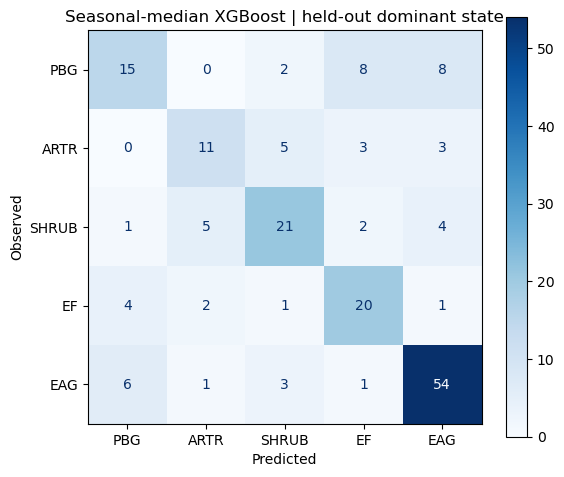

In [8]:
ytr = Utr.argmax(axis=1)
yte = Ute.argmax(axis=1)
state_classifier = xgb.XGBClassifier(
    objective='multi:softprob', num_class=5,
    eval_metric='mlogloss', **XGB_PARAMS
)
if len(np.unique(ytr)) != 5:
    raise ValueError('Training split lacks one or more K5 states; grouped split cannot fit five-class baseline. Inspect state support.')
state_classifier.fit(Xtr,ytr)
state_pred = state_classifier.predict(Xte).astype(int)
state_prob = state_classifier.predict_proba(Xte)

state_results = pd.DataFrame([{
    'direct_accuracy':accuracy_score(yte,state_pred),
    'direct_balanced_accuracy':balanced_accuracy_score(yte,state_pred),
    'membership_argmax_accuracy':accuracy_score(yte,Upred.argmax(axis=1)),
    'majority_train_baseline':np.mean(yte==np.bincount(ytr,minlength=5).argmax()),
    'n_test':len(yte)
}])
display(state_results.round(4))
print(classification_report(yte,state_pred,labels=np.arange(5),
                            target_names=K5_LABELS,zero_division=0))

state_out=test[['PlotID','Year']].reset_index(drop=True).copy()
state_out['observed_state']=np.array(K5_LABELS)[yte]
state_out['predicted_state']=np.array(K5_LABELS)[state_pred]
state_out['max_observed_membership']=Ute.max(axis=1)
for k, label in enumerate(K5_LABELS):
    state_out[f'p_{label}'] = state_prob[:,k]
state_out.to_csv(OUTPUT_DIR/'direct_state_heldout_predictions.csv',index=False)
state_results.to_csv(OUTPUT_DIR/'direct_state_heldout_summary.csv',index=False)
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(yte,state_pred,labels=np.arange(5),
                                        display_labels=K5_LABELS,cmap='Blues',ax=ax)
ax.set(title='Seasonal-median XGBoost | held-out dominant state',
       xlabel='Predicted',ylabel='Observed')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'dominant_state_confusion.png',dpi=200)
plt.show()


## 8. Compact visual diagnostics

These are held-out predictions only. An observed–predicted plot cannot distinguish spatial support mismatch from model error; it can identify which cover groups and membership components warrant further investigation.


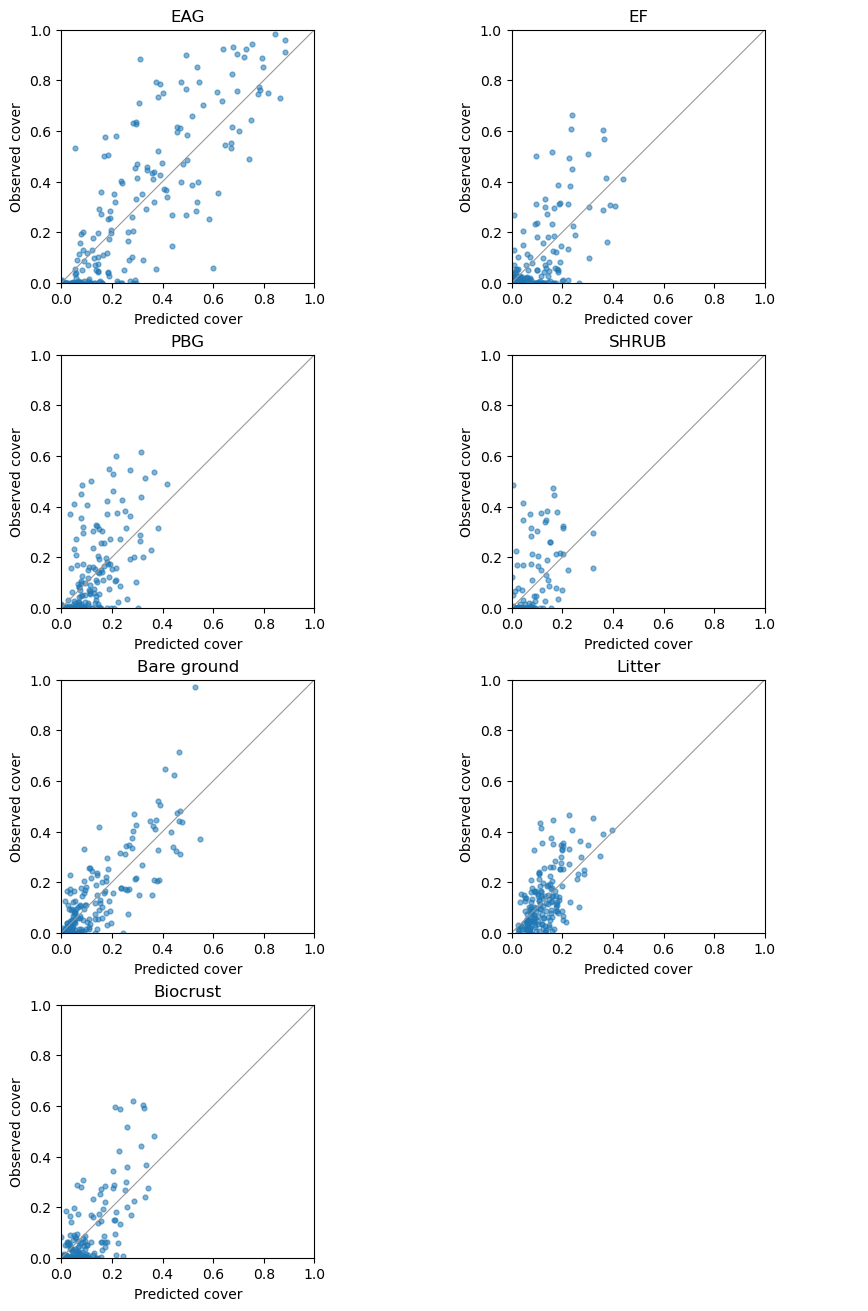

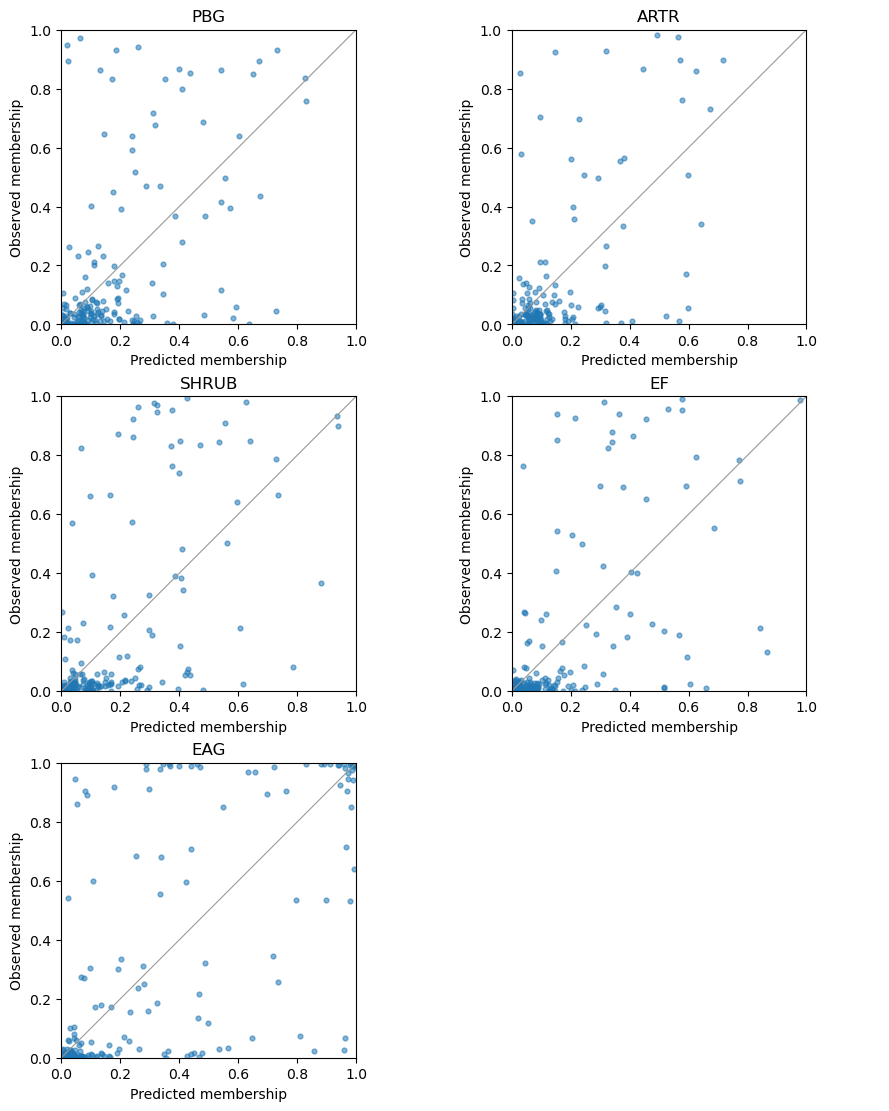

In [9]:
fig,axs=plt.subplots(4,2,figsize=(9,13),constrained_layout=True)
for ax,col,label in zip(axs.flat,FG_COLS,FG_LABELS):
    ax.scatter(fg_predictions[f'{col}_predicted'],fg_predictions[f'{col}_observed'],
               s=12,alpha=.55)
    ax.plot([0,1],[0,1],color='0.6',lw=.8)
    ax.set(xlim=(0,1),ylim=(0,1),title=label,
           xlabel='Predicted cover',ylabel='Observed cover')
    ax.set_aspect('equal',adjustable='box')
axs.flat[-1].axis('off')
plt.savefig(OUTPUT_DIR/'cover_heldout_scatter.png',dpi=200)
plt.show()

fig,axs=plt.subplots(3,2,figsize=(9,11),constrained_layout=True)
for k,(ax,label) in enumerate(zip(axs.flat,K5_LABELS)):
    ax.scatter(Upred[:,k],Ute[:,k],s=12,alpha=.55)
    ax.plot([0,1],[0,1],color='0.6',lw=.8)
    ax.set(xlim=(0,1),ylim=(0,1),title=label,
           xlabel='Predicted membership',ylabel='Observed membership')
    ax.set_aspect('equal',adjustable='box')
axs.flat[-1].axis('off')
plt.savefig(OUTPUT_DIR/'membership_heldout_scatter.png',dpi=200)
plt.show()


## 9. Seasonal feature importance (descriptive)

Mean XGBoost split importance is displayed for the four log-ratio models and the direct state classifier. Strongly correlated months/seasons and bands can substitute for one another; these values are **not** causal or unique contributions.


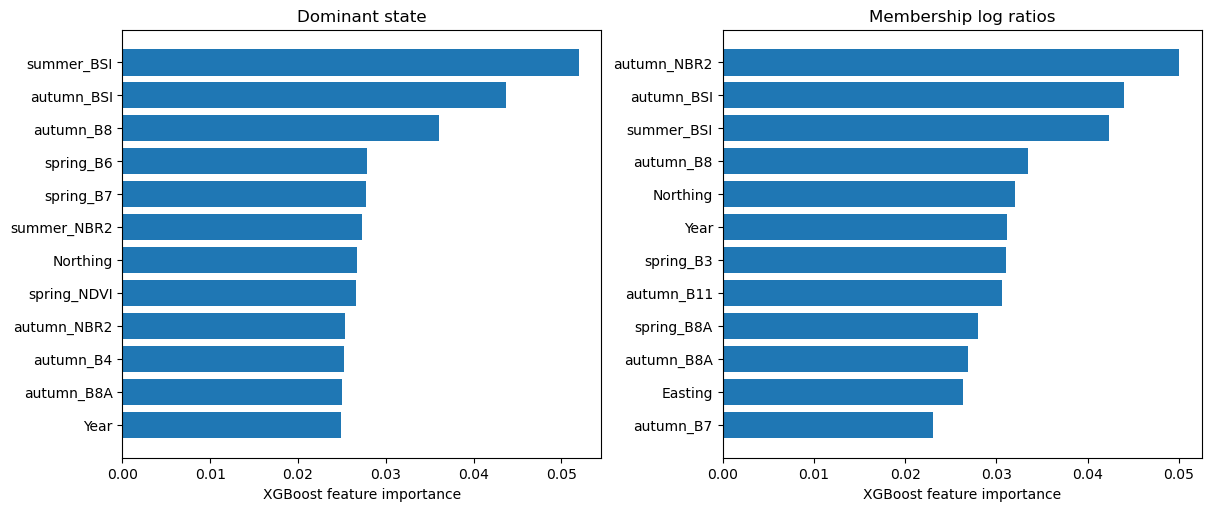

In [10]:
importance = pd.DataFrame({
    'feature':FEATURES,
    'direct_state_importance':state_classifier.feature_importances_,
    'mean_membership_importance':np.mean(
        np.vstack([m.feature_importances_ for m in k5_models]),axis=0)
})
importance.to_csv(OUTPUT_DIR/'seasonal_feature_importance.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for ax,col,title in [
    (axs[0],'direct_state_importance','Dominant state'),
    (axs[1],'mean_membership_importance','Membership log ratios')
]:
    a=importance.nlargest(12,col).sort_values(col)
    ax.barh(a['feature'],a[col])
    ax.set(xlabel='XGBoost feature importance',title=title)
plt.savefig(OUTPUT_DIR/'seasonal_feature_importance.png',dpi=200)
plt.show()


## Interpretation and next checks

- **2016 domain:** historical-site eligibility is inherited from the **actual 2016 export's coordinates**, assuming that Earth Engine export was correctly limited to historical footprints ∩ `keepMask`. This is not a direct polygon intersection in Python. The 2016 CSV is required; 2017–2026 field sites outside its coordinate whitelist are excluded from ML but remain in the master.
- **Join provenance:** exported `plot_id` is intentionally ignored; all median matching is within field year and 2 m of field-point coordinates in EPSG:26911. `ambiguous` or `unmatched` rows are excluded, and their counts are printed.
- **Feature engineering:** 45 seasonal spectral predictors + Year/Easting/Northing = 48; no harmonic features or synthetic missing-month observations.
- **Responses:** seven original fractional cover fields (scaled to 0–1 for modeling) and five **K5 state memberships**, which are not vegetation cover fractions.
- **Validation:** the split groups observations by approximate coordinate location, preventing repeated visits to one location from crossing the train/test boundary. It is not a spatially blocked or out-of-year holdout. The 2026 year is incomplete: autumn coverage and its comparability should be checked before interpreting effects.
- **Prior harmonics results:** accuracy on this new eligible sample is not a controlled comparison to earlier harmonic models unless the exact same rows and folds are used.
